In [1]:
## import the necessary liberaries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
## load the dataset into the data frame
df = pd.read_csv("sales_data_raw.csv")

In [3]:
df.head()

,order_id,order_date,customer_name,city,product,category,quantity,unit_price,payment_method,customer_age,delivery_status,rating
0,ORD1000,2025-02-11,Daniel Okon,Uyo,Laptop,Electronics,4,450000,Card,32.0,Delivered,3.0
1,ORD1001,2025-08-26,Ibrahim Effiong,Port Harcourt,Pen Pack,Stationery,4,1200,Cash,57.0,Delivered,5.0
2,ORD1002,2025-12-18,Emeka Obi,Uyo,Notebook,Stationery,5,1500,Transfer,NaN,Delivered,5.0
3,ORD1003,2025-11-13,Daniel Nwosu,Uyo,Office Chair,Furniture,5,65000,Card,38.0,Delivered,2.0
4,ORD1004,2025-04-11,Joy Nwosu,Lagos,Office Chair,Furniture,4,65000,Card,55.0,Cancelled,NaN


In [4]:
df.tail()

,order_id,order_date,customer_name,city,product,category,quantity,unit_price,payment_method,customer_age,delivery_status,rating
507,ORD1031,2025-03-02,Ifeoma Okon,Abuja,Headphones,Electronics,2,18000,Card,NaN,Delivered,NaN
508,ORD1249,2025-02-27,Blessing Effiong,Calabar,Laptop,Electronics,2,450000,POS,35.0,Delivered,2.0
509,ORD1090,2025-10-20,Grace Obi,Uyo,Office Chair,Furniture,2,65000,Card,52.0,Delivered,5.0
510,ORD1322,2025-02-19,Emeka Eze,Uyo,Notebook,Stationery,4,1500,Cash,39.0,Delivered,5.0
511,ORD1168,2025-12-02,Grace Eze,Abuja,Power Bank,Electronics,5,12000,Transfer,41.0,Delivered,NaN


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 512 entries, 0 to 511
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         512 non-null    object 
 1   order_date       512 non-null    object 
 2   customer_name    512 non-null    object 
 3   city             512 non-null    object 
 4   product          512 non-null    object 
 5   category         512 non-null    object 
 6   quantity         512 non-null    int64  
 7   unit_price       512 non-null    int64  
 8   payment_method   497 non-null    object 
 9   customer_age     471 non-null    float64
 10  delivery_status  512 non-null    object 
 11  rating           451 non-null    float64
dtypes: float64(2), int64(2), object(8)
memory usage: 48.1+ KB


In [6]:
df.describe()

,quantity,unit_price,customer_age,rating
count,512.000000,5.120000e+02,471.000000,451.000000
mean,3.976562,1.784742e+05,40.135881,3.849224
std,22.007725,1.989184e+06,14.566305,1.144792
min,1.000000,1.200000e+03,-5.000000,0.000000
25%,2.000000,1.200000e+04,30.000000,3.000000
50%,3.000000,3.000000e+04,39.000000,4.000000
75%,4.000000,8.500000e+04,52.000000,5.000000
max,500.000000,4.500000e+07,150.000000,9.000000


In [7]:
df.isna().sum()

order_id            0
order_date          0
customer_name       0
city                0
product             0
category            0
quantity            0
unit_price          0
payment_method     15
customer_age       41
delivery_status     0
rating             61
dtype: int64

In [8]:
df.duplicated().sum()

12

In [9]:
df['city'].value_counts()

city
Uyo                122
Port Harcourt      118
Lagos               95
Abuja               64
Calabar             53
Enugu               29
port harcourt        5
 Port Harcourt       5
PORT HARCOURT        3
UYO                  3
 Uyo                 3
ABUJA                3
uyo                  2
 Calabar             2
abuja                1
lagos                1
LAGOS                1
 Lagos               1
calabar              1
Name: count, dtype: int64

In [10]:
df = df.drop_duplicates().copy()
df.shape

(500, 12)

In [11]:
df['city'] = df['city'].str.strip().str.title()
df['city'].value_counts()

city
Port Harcourt    129
Uyo              126
Lagos             97
Abuja             64
Calabar           55
Enugu             29
Name: count, dtype: int64

In [12]:
df = df.drop_duplicates().copy()
df = df[df['quantity'] <= 20].copy()
df_delivered = df[df['delivery_status'] == 'Delivered'].copy()

In [13]:
df.shape

(499, 12)

In [14]:
## handle the invalid ages
df[~df['customer_age'].between(18, 100) & df['customer_age'].notna()][['order_id', 'customer_age']]
## set them to missing
df.loc[~df['customer_age'].between(18, 100), 'customer_age'] = np.nan
# rating can not be 0 and not more than 5
df[~df['rating'].between(1, 5) & df['rating'].notna()][['order_id', 'rating']]
## so anyone that says otherwise return nan
df.loc[~df['rating'].between(1, 5), 'rating'] = np.nan
## investigation and decision
df.groupby('product')['unit_price'].agg(['min', 'max'])

,min,max
product,,
Backpack,15000,15000
Desk,85000,85000
Headphones,18000,18000
Laptop,450000,450000
Notebook,1500,1500
Office Chair,65000,45000000
Pen Pack,1200,1200
Power Bank,12000,12000
Smartphone,220000,220000


In [15]:
# correct the chair price using the product's normal price
df.loc[df['unit_price'] > 1_000_000, 'unit_price'] = 65000

# remove the 500-quantity row
df = df[df['quantity'] <= 20].copy()

df.shape


(499, 12)

In [16]:
df.describe()

,quantity,unit_price,customer_age,rating
count,499.000000,499.000000,457.000000,438.000000
mean,3.008016,91268.136273,40.124726,3.840183
std,1.386950,133272.488502,13.506000,1.110397
min,1.000000,1200.000000,18.000000,1.000000
25%,2.000000,12000.000000,30.000000,3.000000
50%,3.000000,30000.000000,39.000000,4.000000
75%,4.000000,85000.000000,52.000000,5.000000
max,5.000000,450000.000000,64.000000,5.000000


In [17]:
df.isna().sum()

order_id            0
order_date          0
customer_name       0
city                0
product             0
category            0
quantity            0
unit_price          0
payment_method     15
customer_age       42
delivery_status     0
rating             61
dtype: int64

In [18]:
df['payment_method'] = df['payment_method'].fillna('Unknown')
df['payment_method'].value_counts()

payment_method
Card        131
Cash        130
POS         115
Transfer    108
Unknown      15
Name: count, dtype: int64

In [19]:
## fill age with the median age
median_age = df['customer_age'].median()
print(median_age)
df['customer_age'] = df['customer_age'].fillna(median_age)

39.0


In [20]:
## rating: leave it missing
df['rating'].isna().sum()
df['rating'].mean()

3.8401826484018264

In [21]:
df.isna().sum()

order_id            0
order_date          0
customer_name       0
city                0
product             0
category            0
quantity            0
unit_price          0
payment_method      0
customer_age        0
delivery_status     0
rating             61
dtype: int64

In [22]:
## create a revenue
df['total_revenue'] = df['quantity'] * df['unit_price']
df['total_revenue'].sum()

140412400

In [23]:
## check the order status
df['delivery_status'].value_counts()

delivery_status
Delivered    397
Pending       67
Cancelled     35
Name: count, dtype: int64

In [24]:
## make a delivered order table
df_delivered = df[df['delivery_status'] == 'Delivered'].copy()
df_delivered['total_revenue'].sum()

112793100

In [25]:
## revenue by city
all_city = df.groupby('city')['total_revenue'].sum().sort_values(ascending=False)
del_city = df_delivered.groupby('city')['total_revenue'].sum().sort_values(ascending=False)

print(all_city)
print(del_city)

city
Uyo              33894400
Port Harcourt    32785100
Lagos            27365900
Abuja            21455600
Calabar          18426800
Enugu             6484600
Name: total_revenue, dtype: int64
city
Port Harcourt    29453900
Uyo              24145500
Lagos            22401700
Abuja            19307000
Calabar          11567400
Enugu             5917600
Name: total_revenue, dtype: int64


In [26]:
## revenue by category
df_delivered.groupby('category')['total_revenue'].sum().sort_values(ascending=False)

category
Electronics    87934000
Furniture      19235000
Accessories     5295000
Stationery       329100
Name: total_revenue, dtype: int64

In [27]:
## revenue by product
df_delivered.groupby('product')['total_revenue'].sum().sort_values(ascending=False)

product
Laptop          56250000
Smartphone      28600000
Office Chair    10140000
Desk             9095000
Wristwatch       3810000
Headphones       1872000
Backpack         1485000
Power Bank       1212000
Pen Pack          177600
Notebook          151500
Name: total_revenue, dtype: int64

In [28]:
print(df['order_date'].dtype)
print(df_delivered['order_date'].dtype)

object
object


In [29]:
df['order_date'] = pd.to_datetime(df['order_date'], format='mixed', dayfirst=True, errors='coerce')
print(df['order_date'].dtype)
print(df['order_date'].isna().sum())

datetime64[ns]
0


In [30]:
df_delivered = df[df['delivery_status'] == 'Delivered'].copy()
print(df_delivered['order_date'].dtype)
print(len(df_delivered))

datetime64[ns]
397


In [31]:
df['order_date'].head()
df['order_date'].dtype

dtype('<M8[ns]')

In [32]:
df_delivered = df[df['delivery_status'] == 'Delivered'].copy()
print(df_delivered['order_date'].dtype)
print(len(df_delivered))

datetime64[ns]
397


In [33]:
## monthly trend
df_delivered['month'] = df_delivered['order_date'].dt.to_period('M')
monthly = df_delivered.groupby('month')['total_revenue'].sum()
monthly

month
2025-01     7373100
2025-02    16583300
2025-03     6450200
2025-04     7611900
2025-05     6055500
2025-06    15112500
2025-07     9676400
2025-08    12853800
2025-09     5181400
2025-10     8996000
2025-11     5748800
2025-12    11150200
Freq: M, Name: total_revenue, dtype: int64

In [34]:
d1 = pd.to_datetime(df['order_date'], format='%Y-%m-%d', errors='coerce')
d2 = pd.to_datetime(df['order_date'], format='%d/%m/%Y', errors='coerce')
df['order_date'] = d1.fillna(d2)
df['order_date'].isna().sum()   # should be 0

0

In [35]:
df_delivered.groupby('city')['total_revenue'].sum().sort_values(ascending=False)

city
Port Harcourt    29453900
Uyo              24145500
Lagos            22401700
Abuja            19307000
Calabar          11567400
Enugu             5917600
Name: total_revenue, dtype: int64

In [36]:
df

,order_id,order_date,customer_name,city,product,category,quantity,unit_price,payment_method,customer_age,delivery_status,rating,total_revenue
0,ORD1000,2025-02-11,Daniel Okon,Uyo,Laptop,Electronics,4,450000,Card,32.0,Delivered,3.0,1800000
1,ORD1001,2025-08-26,Ibrahim Effiong,Port Harcourt,Pen Pack,Stationery,4,1200,Cash,57.0,Delivered,5.0,4800
2,ORD1002,2025-12-18,Emeka Obi,Uyo,Notebook,Stationery,5,1500,Transfer,39.0,Delivered,5.0,7500
3,ORD1003,2025-11-13,Daniel Nwosu,Uyo,Office Chair,Furniture,5,65000,Card,38.0,Delivered,2.0,325000
4,ORD1004,2025-04-11,Joy Nwosu,Lagos,Office Chair,Furniture,4,65000,Card,55.0,Cancelled,NaN,260000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,ORD1495,2025-08-17,Ibrahim Etim,Lagos,Office Chair,Furniture,3,65000,Transfer,47.0,Delivered,4.0,195000
496,ORD1496,2025-07-12,Aisha Musa,Calabar,Smartphone,Electronics,1,220000,Card,33.0,Delivered,4.0,220000
497,ORD1497,2025-05-12,Joy Okafor,Lagos,Power Bank,Electronics,3,12000,POS,36.0,Delivered,5.0,36000
498,ORD1498,2025-12-18,Ibrahim Obi,Port Harcourt,Wristwatch,Accessories,1,30000,Cash,29.0,Delivered,5.0,30000


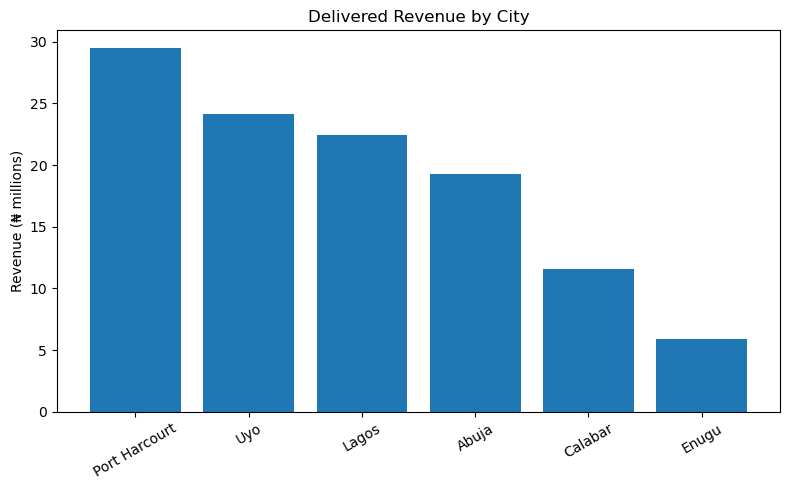

In [37]:
#import matplotlib.pyplot as plt

city_rev = df_delivered.groupby('city')['total_revenue'].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(city_rev.index, city_rev.values / 1e6)
plt.title('Delivered Revenue by City')
plt.ylabel('Revenue (₦ millions)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

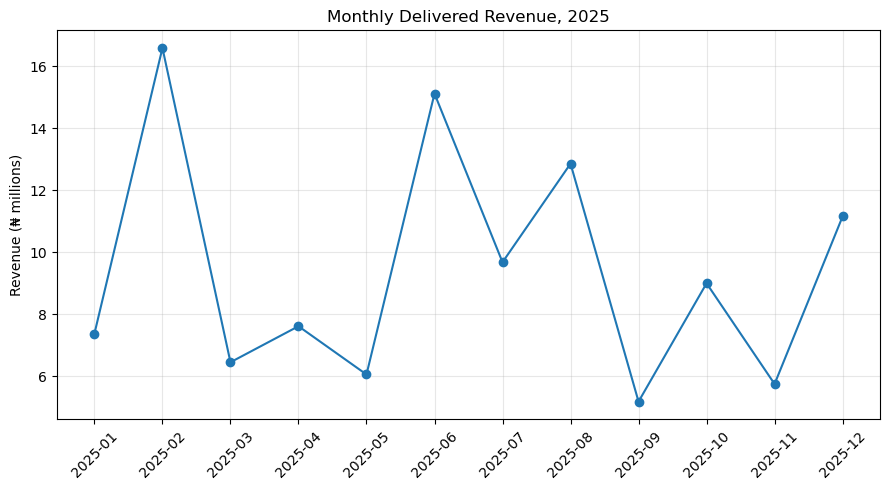

In [38]:
monthly_m = monthly / 1e6

plt.figure(figsize=(9, 5))
plt.plot(monthly_m.index.astype(str), monthly_m.values, marker='o')
plt.title('Monthly Delivered Revenue, 2025')
plt.ylabel('Revenue (₦ millions)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

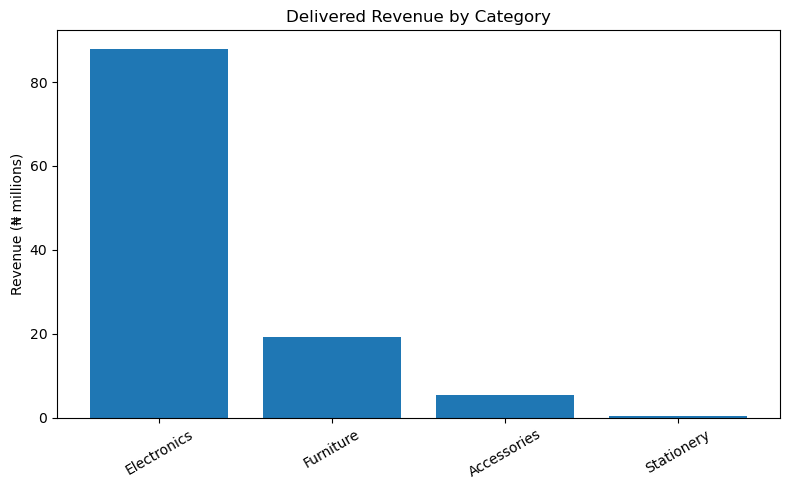

In [39]:
#import matplotlib.pyplot as plt

category_rev = df_delivered.groupby('category')['total_revenue'].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(category_rev.index, category_rev.values / 1e6)
plt.title('Delivered Revenue by Category')
plt.ylabel('Revenue (₦ millions)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

#### Retail Sales Analysis Report, 2025
Prepared by: Isaac | October 2026 | Tools: Python (pandas, matplotlib), Jupyter Notebook
Executive Summary
This report analyses 512 raw retail order records covering January to December 2025 across six Nigerian cities. After cleaning, 499 orders remained. Counting only delivered orders (397 orders), the business earned ₦112.8 million.
Key findings:
• Port Harcourt is the top city (₦29.5M, 26% of revenue). Enugu is the weakest (₦5.9M, 5%).
• Electronics generates about 78% of revenue. Laptops alone contribute 49.9% (₦56.3M).
• Revenue peaked in February (₦16.6M) and June (₦15.1M), and was lowest in September (₦5.2M).
• About ₦27.6M of order value is tied up in pending or cancelled orders.
• Data quality mattered: before cleaning, two typing errors inflated revenue from ₦140.4M to about ₦320.9M and produced the wrong top city and category.
1. Objectives
The analysis set out to answer five business questions:
1. Which cities generate the most and least revenue?
2. Which product categories and products drive revenue?
3. How does revenue change month by month?
4. How healthy is order fulfilment (delivered, pending, cancelled)?
5. How satisfied are customers, and how do they pay?
2. Data Description
The dataset is a practice dataset of retail orders, generated with a Python script and deliberately seeded with common data problems.
Item
Detail
Raw size
512 rows, 12 columns
Period
January to December 2025
Cities
Uyo, Port Harcourt, Lagos, Abuja, Calabar, Enugu
Categories
Electronics, Furniture, Accessories, Stationery
Columns
order_id, order_date, customer_name, city, product, category, quantity, unit_price, payment_method, customer_age, delivery_status, rating
3. Data Cleaning
Every decision was checked against the data before it was applied.
Problem found
Action taken
Reason
12 duplicate rows
Removed
Exact copies would double-count sales
City labels in mixed case and with extra spaces (for example UYO, uyo, " Uyo ")
Trimmed spaces and standardised to Title Case
Otherwise one city is split into several groups
order_date stored as text, in two formats (yyyy-mm-dd and dd/mm/yyyy)
Parsed each format explicitly into a real date type
Needed for monthly analysis; guessing the format can swap day and month
3 impossible ages (-5, 0, 150)
Set to missing
True value unknown
2 impossible ratings (0 and 9)
Set to missing
Valid ratings are 1 to 5
Unit price of ₦45,000,000 for an office chair
Corrected to ₦65,000
Every other office chair is priced at ₦65,000, so this was a typing error
Quantity of 500 for a notebook order
Row removed
True quantity cannot be known
Missing payment method (15)
Labelled "Unknown"
A category cannot be estimated reliably
Missing age (42, including the invalid ones)
Filled with the median age (39)
Median is not affected by extreme values
Missing rating (61)
Left as missing
A rating is an opinion; filling it would invent data
Result: 499 clean rows. A total_revenue column was then created as quantity multiplied by unit price.
Why cleaning mattered
Without fixing the two typing errors, total revenue appeared as about ₦320.9M, Lagos appeared to be the top city and Furniture the top category. After cleaning, total order value for all orders is ₦140.4M, and the real leaders are different. One bad value changed the business conclusion.
4. Definition of Sales
Orders fall into three statuses:
Status
Orders
Order value
Delivered
397 (79.6%)
₦112.8M
Pending
67 (13.4%)
₦19.4M
Cancelled
35 (7.0%)
₦8.2M
Cancelled and pending orders have not produced income. Therefore, all revenue figures in this report use delivered orders only, unless stated otherwise. This choice matters: if all orders were counted, Uyo (₦33.9M) would edge out Port Harcourt (₦32.8M) as the top city.
5. Findings
5.1 Revenue by city
City
Revenue
Share
Delivered orders
Average order value
Port Harcourt
₦29.5M
26.1%
108
₦272,700
Uyo
₦24.1M
21.4%
96
₦251,500
Lagos
₦22.4M
19.9%
80
₦280,000
Abuja
₦19.3M
17.1%
46
₦419,700
Calabar
₦11.6M
10.3%
42
₦275,400
Enugu
₦5.9M
5.2%
25
₦236,700
Port Harcourt leads because of order volume (108 orders). Abuja has few orders but by far the highest average order value (₦419,700), which suggests larger purchases, probably of higher-priced electronics. Enugu is the weakest on both revenue and order count.
5.2 Revenue by category
Category
Revenue
Share
Electronics
₦87.9M
78.0%
Furniture
₦19.2M
17.1%
Accessories
₦5.3M
4.7%
Stationery
₦0.3M
0.3%
5.3 Revenue by product
Product
Revenue
Units sold
Laptop
₦56.25M
125
Smartphone
₦28.6M
130
Office Chair
₦10.1M
156
Desk
₦9.1M
107
Wristwatch
₦3.8M
127
Headphones
₦1.9M
104
Backpack
₦1.5M
99
Power Bank
₦1.2M
101
Pen Pack
₦0.18M
148
Notebook
₦0.15M
101
Sales volume and revenue tell different stories. Office Chairs sell the most units (156) but rank third in revenue, while Laptops sell 125 units yet bring in half of all revenue. Laptops and Smartphones together contribute about 75% of revenue.
5.4 Monthly trend
Month
Revenue
Month
Revenue
January
₦7.4M
July
₦9.7M
February
₦16.6M
August
₦12.9M
March
₦6.5M
September
₦5.2M
April
₦7.6M
October
₦9.0M
May
₦6.1M
November
₦5.7M
June
₦15.1M
December
₦11.2M
February and June are the peak months, and September and November are the weakest. The pattern is uneven rather than a steady trend, so a single high month should not be read as growth.
5.5 Customer satisfaction and payment
The average rating of delivered orders is 3.87 out of 5.
Category
Average rating
Accessories
3.95
Electronics
3.91
Stationery
3.88
Furniture
3.73
Furniture has the lowest rating, which is worth investigating given it is the second-largest category.
By payment method, Card accounts for 28.4% of delivered revenue, POS for 26.3%, Cash for 23.8%, Transfer for 19.7%, and Unknown for 1.8%. Payment is spread fairly evenly, so the business should support all four methods.
6. Recommendations
1. Protect electronics supply. Electronics is 78% of revenue and two products are 75%. Make sure Laptops and Smartphones are always in stock, and consider the risk of depending on so few products.
2. Reduce pending and cancelled orders. About ₦27.6M of order value is not yet earned or was lost. Faster fulfilment and follow-up on pending orders is the quickest way to raise revenue without finding new customers.
3. Investigate Enugu. It has the fewest orders and the lowest revenue. Check whether the cause is market size, delivery coverage or lack of marketing.
4. Learn from Abuja. Its average order value is the highest. Try to understand which products drive this and whether the approach can be repeated in other cities.
5. Plan for seasonal dips. Run promotions or bundles in the weaker months (September, November, May, March).
6. Review furniture quality or delivery. Furniture has the lowest customer rating.
7. Improve data collection. Missing ages (42), ratings (61) and payment methods (15) limit future analysis. Make these fields compulsory at the point of sale, and add validation to block impossible values such as a quantity of 500 or a price with extra zeros.
7. Limitations
• The data is a simulated practice dataset, so the patterns here (including monthly peaks and city rankings) illustrate the method and should not be treated as real market evidence.
• The analysis covers revenue, not profit. No cost data was available.
• The office chair price was corrected on the assumption that its normal price of ₦65,000 applies. The notebook order was removed because its true quantity is unknown.
• Missing ages were filled with the median, so age-based conclusions would be unreliable. About 12% of ratings are missing, so satisfaction figures reflect only customers who rated.
• Only one year of data is available, so year-on-year growth cannot be measured.
8. Conclusion
The analysis shows a business whose revenue is concentrated in a few places and products: Port Harcourt as the top city, and Electronics, led by Laptops, as the main driver. The biggest opportunities are reducing unfulfilled orders, growing weaker markets such as Enugu, and smoothing the seasonal dips. The most important technical lesson is that data cleaning changes the answer: without it, a single typing error would have pointed the business at the wrong city and the wrong category.
Appendix: Method Summary
1. Loaded and inspected the data (shape, types, summary statistics, value counts).
2. Cleaned duplicates, text labels, dates, invalid values and outliers.
3. Handled missing values column by column.
4. Created total_revenue and filtered to delivered orders.
5. Summarised revenue with groupby by city, category, product and month.
6. Visualised results with bar and line charts.